# Does the shorter argument win?

Compare opening replies in the paper's original **training pairs**. Each pair has two top-level openings under the same OP post. One opens a branch that eventually earned an OP-awarded delta. The other is the published comparison. The pair construction matched vocabulary overlap in the opening replies and applied a minimum-length filter. These results describe the matched sample and its eventual branch outcomes.

This differs from the [one-hour argument-length classifier](../models-threads/argument-length/argument_length.ipynb), which predicted deltas in a fixed follow-up window across eligible branches. The [standalone script](compare_paired_length.py) saves each analysis run separately. Set `RUN_ID` to revisit a run. The figure requires Matplotlib.

[Original pairing method, §4.1](https://www.cs.cornell.edu/~cristian/pdfs/winning_arguments.pdf)

In [1]:
import json
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/paired-argument-length"
SCRIPT = REPO / "project/notebooks/paired-argument-length/compare_paired_length.py"
RUN_ID = None

runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    subprocess.run([sys.executable, str(SCRIPT)], check=True)
    runs = sorted(RUNS.glob("*/results.json"))
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
report = json.loads(report_path.read_text())
pairs = pd.read_parquet(report_path.parent / "pairs.parquet")
print(f"{len(pairs):,} of {report['published_pairs']:,} published pairs across {report['discussions']:,} OP posts")
for reason, count in report["excluded"].items():
    print(f"Excluded {count:,}: {reason}")

3,451 of 3,456 published pairs across 2,507 OP posts
Excluded 5: unusable opening text


## Compare lengths within each pair

Subtract the published comparison's length from the winner's. Negative values mean the winner was shorter, and zero is a tie. Word count is the primary measure. Sentence count and average words per sentence are secondary. We use the same text cleaning and counting rules as the branch-level length analysis. The primary percentage uses unequal-word-count pairs, with ties reported separately. The 95% interval resamples whole OP discussions because a post can contribute several pairs.

In [2]:
summary = pd.DataFrame(report["length_metrics"]).set_index("metric")
summary["winner_lower_pct"] = 100 * summary["winner_lower_rate"]
display(summary[[
    "winner_lower", "winner_higher", "ties", "winner_lower_pct", "winner_median",
    "comparison_median", "median_winner_minus_comparison",
]].round(2))
lo, hi = report["shorter_word_count_95_ci"]
print(f"Shorter opening win share: {summary.at['word_count', 'winner_lower_rate']:.2%} "
      f"(95% discussion-bootstrap interval {lo:.2%}–{hi:.2%})")

,winner_lower,winner_higher,ties,winner_lower_pct,winner_median,comparison_median,median_winner_minus_comparison
metric,,,,,,,
word_count,1276,2166,9,37.07,201.00,156.00,36.00
sentence_count,1259,1986,206,38.80,11.00,9.00,2.00
average_sentence_length,1635,1812,4,47.43,18.27,17.77,0.44


Shorter opening win share: 37.07% (95% discussion-bootstrap interval 35.38%–38.78%)


## Does the result depend on the size of the gap?

Each point shows how often the shorter opening won among pairs in that word-gap group. A value of 50% means the shorter and longer openings won equally often in that group. This is a relative win share within one-winner pairs. The design gives no estimate of the absolute probability that a reply earns a delta. Differences in argument quality, timing, and engagement can still matter within a pair.

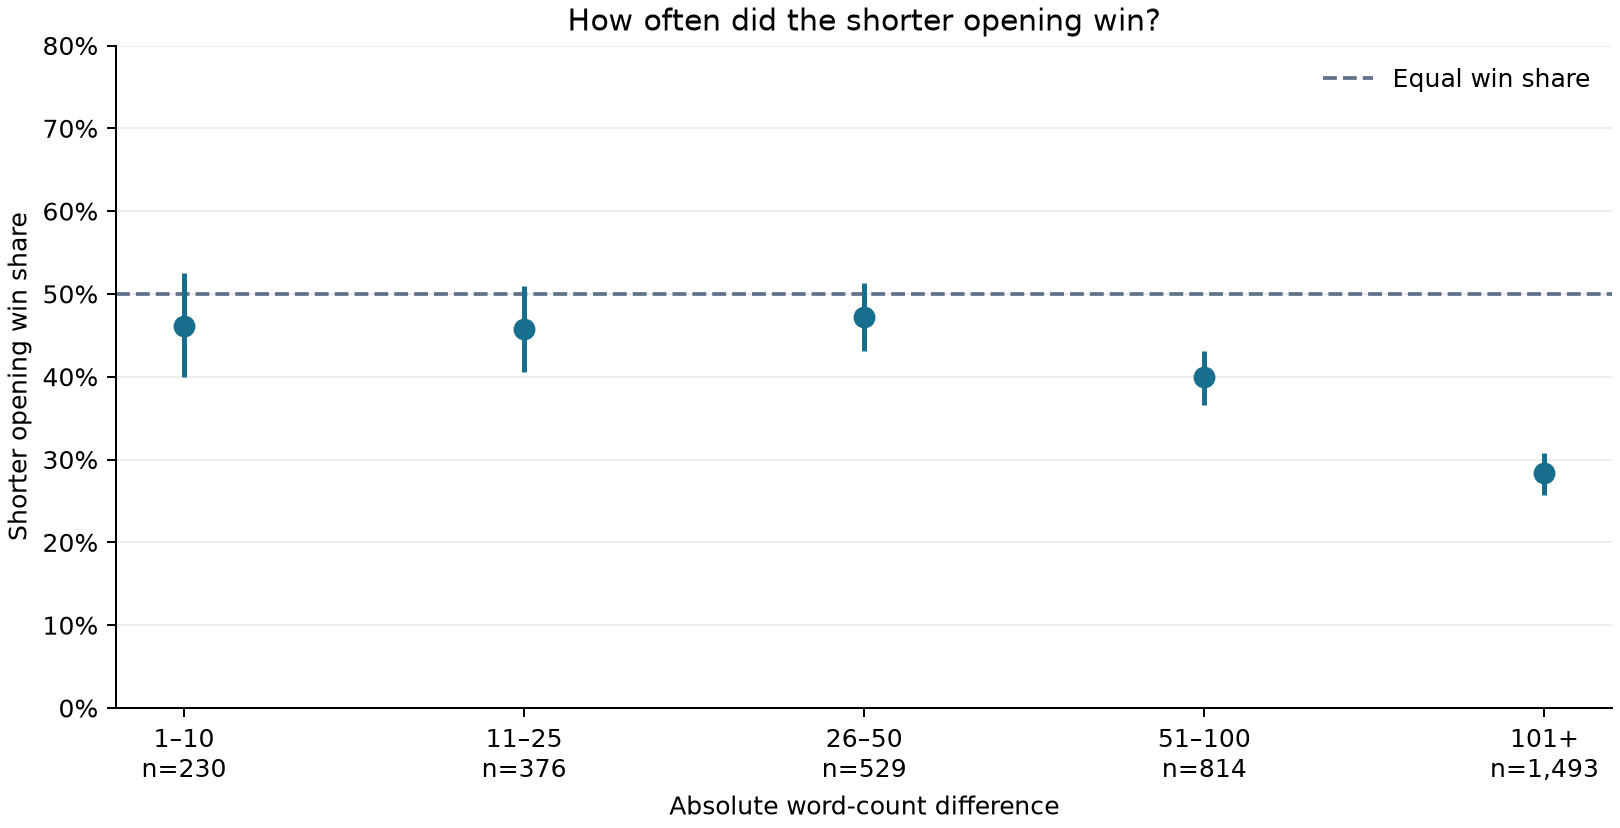

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

gaps = pd.DataFrame(report["word_gap_groups"]).set_index("word_gap")
intervals = np.asarray(gaps["ci_95"].tolist())
x = np.arange(len(gaps))
fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
ax.axhline(0.5, color="#61738a", linestyle="--", label="Equal win share")
ax.vlines(x, intervals[:, 0], intervals[:, 1], color="#176e8d", linewidth=2)
ax.scatter(x, gaps["shorter_win_rate"], color="#176e8d", s=60, zorder=3)
ax.set_xticks(x, [f"{gap}\nn={count:,}" for gap, count in zip(gaps.index, gaps["pairs"])])
ax.set(title="How often did the shorter opening win?", xlabel="Absolute word-count difference",
       ylabel="Shorter opening win share", ylim=(0, 0.8))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", alpha=0.22)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig(report_path.parent / "shorter_win_by_word_gap.png", dpi=180, facecolor="white")
plt.show()